In [157]:
import pandas as pd
import scipy.stats as stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
import statsmodels.api as sm

Study Questions

1. What is the overall distribution of employee performance ratings at INX Future Inc., and to what extent is poor performance prevalent?
2. How does employee performance vary across departments and job roles?
3. Which employee characteristics are significantly associated with performance ratings?
4. How accurately can employee performance ratings be predicted using available employee data?
5. What evidence-based interventions can INX Future Inc. consider to improve employee performance, and how can their effectiveness be evaluated?

In [158]:
df = pd.read_excel("../../data/raw/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls")

In [159]:
pd.set_option('display.max_columns', None)
df.head()

,EmpNumber,Age,Gender,EducationBackground,MaritalStatus,EmpDepartment,EmpJobRole,BusinessTravelFrequency,DistanceFromHome,EmpEducationLevel,EmpEnvironmentSatisfaction,EmpHourlyRate,EmpJobInvolvement,EmpJobLevel,EmpJobSatisfaction,NumCompaniesWorked,OverTime,EmpLastSalaryHikePercent,EmpRelationshipSatisfaction,TotalWorkExperienceInYears,TrainingTimesLastYear,EmpWorkLifeBalance,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition,PerformanceRating
0,E1001000,32,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,10,3,4,55,3,2,4,1,No,12,4,10,2,2,10,7,0,8,No,3
1,E1001006,47,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,14,4,4,42,3,2,1,2,No,12,4,20,2,3,7,7,1,7,No,3
2,E1001007,40,Male,Life Sciences,Married,Sales,Sales Executive,Travel_Frequently,5,4,4,48,2,3,1,5,Yes,21,3,20,2,3,18,13,1,12,No,4
3,E1001009,41,Male,Human Resources,Divorced,Human Resources,Manager,Travel_Rarely,10,4,2,73,2,5,4,3,No,15,2,23,2,2,21,6,12,6,No,3
4,E1001010,60,Male,Marketing,Single,Sales,Sales Executive,Travel_Rarely,16,4,1,84,3,2,1,8,No,14,4,10,1,3,2,2,2,2,No,3


In [160]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 28 columns):
 #   Column                        Non-Null Count  Dtype 
---  ------                        --------------  ----- 
 0   EmpNumber                     1200 non-null   object
 1   Age                           1200 non-null   int64 
 2   Gender                        1200 non-null   object
 3   EducationBackground           1200 non-null   object
 4   MaritalStatus                 1200 non-null   object
 5   EmpDepartment                 1200 non-null   object
 6   EmpJobRole                    1200 non-null   object
 7   BusinessTravelFrequency       1200 non-null   object
 8   DistanceFromHome              1200 non-null   int64 
 9   EmpEducationLevel             1200 non-null   int64 
 10  EmpEnvironmentSatisfaction    1200 non-null   int64 
 11  EmpHourlyRate                 1200 non-null   int64 
 12  EmpJobInvolvement             1200 non-null   int64 
 13  EmpJobLevel       

In [161]:
ordinal_columns = ["EmpEducationLevel",
"EmpJobSatisfaction",
"PerformanceRating",
"EmpWorkLifeBalance",
"EmpRelationshipSatisfaction",
"EmpEnvironmentSatisfaction",
"EmpJobInvolvement",
"EmpJobLevel"]

for col in ordinal_columns:
    df[col] = df[col].astype("category")
    df[col] = df[col].cat.as_ordered()

In [162]:
df['OverTime'].value_counts()

OverTime
No     847
Yes    353
Name: count, dtype: int64

In [163]:
df['Attrition'].value_counts()

Attrition
No     1022
Yes     178
Name: count, dtype: int64

In [164]:
df[['Attrition', 'OverTime']].dtypes

Attrition    object
OverTime     object
dtype: object

In [165]:
df['Attrition'] = df['Attrition'].map({'Yes': True, 'No': False}).astype('bool')
df['OverTime'] = df['OverTime'].map({'Yes': True, 'No': False}).astype('bool')

In [166]:
df[ordinal_columns + ["Attrition", "OverTime"]].dtypes

EmpEducationLevel              category
EmpJobSatisfaction             category
PerformanceRating              category
EmpWorkLifeBalance             category
EmpRelationshipSatisfaction    category
EmpEnvironmentSatisfaction     category
EmpJobInvolvement              category
EmpJobLevel                    category
Attrition                          bool
OverTime                           bool
dtype: object

In [167]:
df['EmpJobInvolvement'].value_counts()

EmpJobInvolvement
3    724
2    294
4    112
1     70
Name: count, dtype: int64

In [168]:
df['EducationBackground'].value_counts()

EducationBackground
Life Sciences       492
Medical             384
Marketing           137
Technical Degree    100
Other                66
Human Resources      21
Name: count, dtype: int64

In [169]:
df['EmpJobRole'].value_counts()

EmpJobRole
Sales Executive              270
Developer                    236
Manager R&D                   94
Research Scientist            77
Sales Representative          69
Laboratory Technician         64
Senior Developer              52
Manager                       51
Finance Manager               49
Human Resources               45
Technical Lead                38
Manufacturing Director        33
Healthcare Representative     33
Data Scientist                20
Research Director             19
Business Analyst              16
Senior Manager R&D            15
Delivery Manager              12
Technical Architect            7
Name: count, dtype: int64

In [170]:
df['BusinessTravelFrequency'].value_counts()

BusinessTravelFrequency
Travel_Rarely        846
Travel_Frequently    222
Non-Travel           132
Name: count, dtype: int64

In [171]:
df.shape

(1200, 28)

In [172]:
df.isnull().sum()

EmpNumber                       0
Age                             0
Gender                          0
EducationBackground             0
MaritalStatus                   0
EmpDepartment                   0
EmpJobRole                      0
BusinessTravelFrequency         0
DistanceFromHome                0
EmpEducationLevel               0
EmpEnvironmentSatisfaction      0
EmpHourlyRate                   0
EmpJobInvolvement               0
EmpJobLevel                     0
EmpJobSatisfaction              0
NumCompaniesWorked              0
OverTime                        0
EmpLastSalaryHikePercent        0
EmpRelationshipSatisfaction     0
TotalWorkExperienceInYears      0
TrainingTimesLastYear           0
EmpWorkLifeBalance              0
ExperienceYearsAtThisCompany    0
ExperienceYearsInCurrentRole    0
YearsSinceLastPromotion         0
YearsWithCurrManager            0
Attrition                       0
PerformanceRating               0
dtype: int64

In [173]:
df.duplicated().sum()

0

In [174]:
df['MaritalStatus'].value_counts()

MaritalStatus
Married     548
Single      384
Divorced    268
Name: count, dtype: int64

In [175]:
df['EmpNumber'].duplicated().sum()

0

In [176]:
df.describe()

,Age,DistanceFromHome,EmpHourlyRate,NumCompaniesWorked,EmpLastSalaryHikePercent,TotalWorkExperienceInYears,TrainingTimesLastYear,ExperienceYearsAtThisCompany,ExperienceYearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000,1200.000000
mean,36.918333,9.165833,65.981667,2.665000,15.222500,11.330000,2.785833,7.077500,4.291667,2.194167,4.105000
std,9.087289,8.176636,20.211302,2.469384,3.625918,7.797228,1.263446,6.236899,3.613744,3.221560,3.541576
min,18.000000,1.000000,30.000000,0.000000,11.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,2.000000,48.000000,1.000000,12.000000,6.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,7.000000,66.000000,2.000000,14.000000,10.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,14.000000,83.000000,4.000000,18.000000,15.000000,3.000000,10.000000,7.000000,3.000000,7.000000
max,60.000000,29.000000,100.000000,9.000000,25.000000,40.000000,6.000000,40.000000,18.000000,15.000000,17.000000


In [177]:
summary = df.describe()

Q1 = summary.loc['25%']
Q3 = summary.loc['75%']

iqr = Q3 - Q1

lower_bound = Q1 - 1.5 * iqr
upper_bound = Q3 + 1.5 * iqr

outliers = []

for col in summary.columns:
    outlier_count = (

        (df[col] < lower_bound[col]) |
        (df[col] > upper_bound[col])

    ).sum()

    outliers.append({
        "Variable": col,
        "Lower Bound": lower_bound[col],
        "Upper Bound": upper_bound[col],
        "Outlier Count": outlier_count,
        "Outlier Percentage": round(
            (outlier_count / len(df)) * 100, 2
        )
    })



outlier_summary = pd.DataFrame(outliers)

display(outlier_summary)


,Variable,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,Age,10.5,62.5,0,0.00
1,DistanceFromHome,-16.0,32.0,0,0.00
2,EmpHourlyRate,-4.5,135.5,0,0.00
3,NumCompaniesWorked,-3.5,8.5,39,3.25
4,EmpLastSalaryHikePercent,3.0,27.0,0,0.00
5,TotalWorkExperienceInYears,-7.5,28.5,51,4.25
6,TrainingTimesLastYear,0.5,4.5,188,15.67
7,ExperienceYearsAtThisCompany,-7.5,20.5,56,4.67
8,ExperienceYearsInCurrentRole,-5.5,14.5,16,1.33
9,YearsSinceLastPromotion,-4.5,7.5,88,7.33


In [178]:
df['EmpHourlyRate'].skew()

-0.035164888157941436

/opt/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


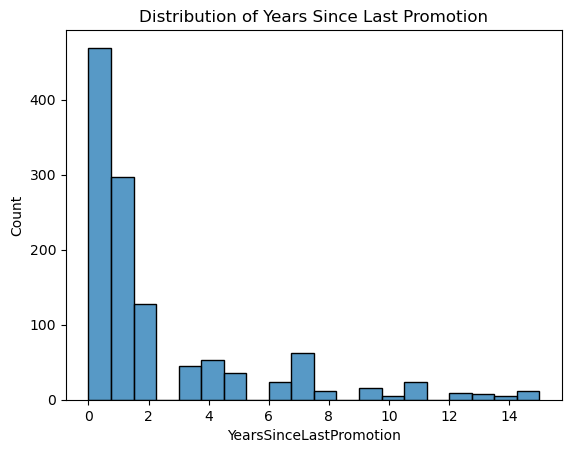

In [179]:
sns.histplot(df["YearsSinceLastPromotion"], bins=20)
plt.title("Distribution of Years Since Last Promotion")
plt.show()

In [180]:
df['YearsSinceLastPromotion'].skew()

1.9749315589155791

In [181]:
from scipy import stats
import numpy as np

numerical_data = df.select_dtypes(include="number")

z_scores = np.abs(stats.zscore(numerical_data, nan_policy="omit"))

threshold = 3

outlier_counts = (z_scores > threshold).sum(axis=0)

outlier_summary = pd.DataFrame({
    "Variable": numerical_data.columns,
    "Outlier Count": outlier_counts.values,
    "Outlier Percentage": (
        outlier_counts.values / len(df) * 100
    ).round(2)
})

display(outlier_summary)

,Variable,Outlier Count,Outlier Percentage
0,Age,0,0.00
1,DistanceFromHome,0,0.00
2,EmpHourlyRate,0,0.00
3,NumCompaniesWorked,0,0.00
4,EmpLastSalaryHikePercent,0,0.00
5,TotalWorkExperienceInYears,11,0.92
6,TrainingTimesLastYear,0,0.00
7,ExperienceYearsAtThisCompany,22,1.83
8,ExperienceYearsInCurrentRole,12,1.00
9,YearsSinceLastPromotion,33,2.75


In [182]:
df["DistanceFromHome"].nunique()


29

In [183]:
definitions = pd.read_excel(
    "../../data/raw/INX_Future_Inc_Employee_Performance_CDS_Project2_Data_V1.8.xls",
    sheet_name="Data Definitions",
    header=None
)

display(definitions)

,0,1
0,NaN,NaN
1,NaN,NaN
2,EmpEducationLevel,1 'Below College'
3,NaN,2 'College'
4,NaN,3 'Bachelor'
5,NaN,4 'Master'
6,NaN,5 'Doctor'
7,NaN,NaN
8,EmpEnvironmentSatisfaction,1 'Low'
9,NaN,2 'Medium'


### What is the overall distribution of employee performance ratings at INX Future Inc.?

In [184]:
df['PerformanceRating'].value_counts()

PerformanceRating
3    874
2    194
4    132
Name: count, dtype: int64

In [204]:
percentage_overall_performance = df['PerformanceRating'].value_counts(normalize='index')*100
percentage_overall_performance


PerformanceRating
3    72.833333
2    16.166667
4    11.000000
Name: proportion, dtype: float64

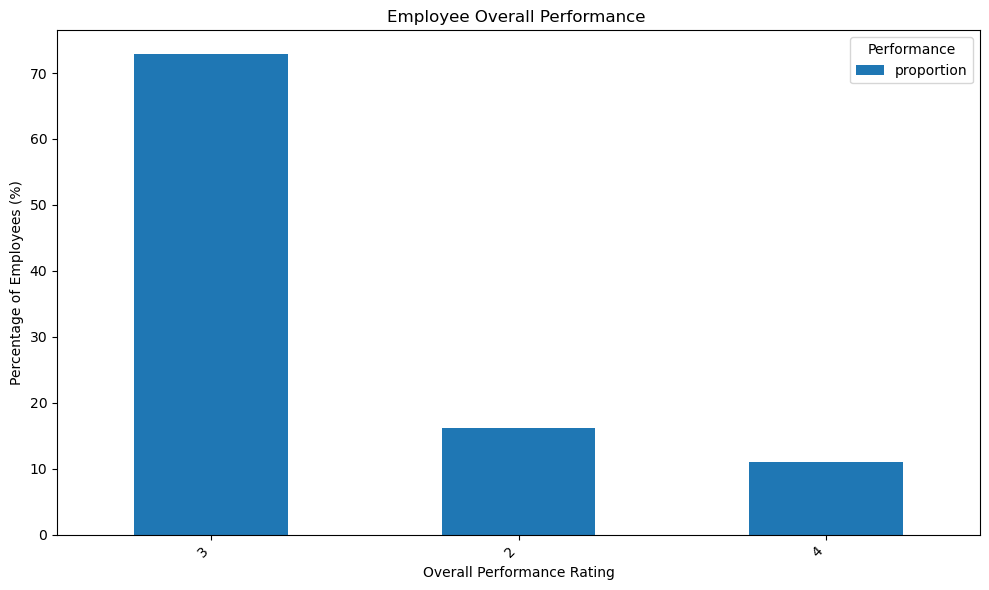

In [206]:
percentage_overall_performance.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Employee Overall Performance ')
plt.xlabel('Overall Performance Rating')
plt.ylabel('Percentage of Employees (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Performance')
plt.tight_layout()
plt.show()

### How does employee performance vary across departments and job roles?

In [194]:
df['EmpDepartment'].value_counts()

EmpDepartment
Sales                     373
Development               361
Research & Development    343
Human Resources            54
Finance                    49
Data Science               20
Name: count, dtype: int64

In [192]:
df['EmpDepartment'].groupby(df['PerformanceRating']).value_counts()

/var/folders/22/sgmzcv3j7nz5t7bc1byt1xlh0000gn/T/ipykernel_1285/3044583138.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df['EmpDepartment'].groupby(df['PerformanceRating']).value_counts()


PerformanceRating  EmpDepartment         
2                  Sales                      87
                   Research & Development     68
                   Finance                    15
                   Development                13
                   Human Resources            10
                   Data Science                1
3                  Development               304
                   Sales                     251
                   Research & Development    234
                   Human Resources            38
                   Finance                    30
                   Data Science               17
4                  Development                44
                   Research & Development     41
                   Sales                      35
                   Human Resources             6
                   Finance                     4
                   Data Science                2
Name: count, dtype: int64

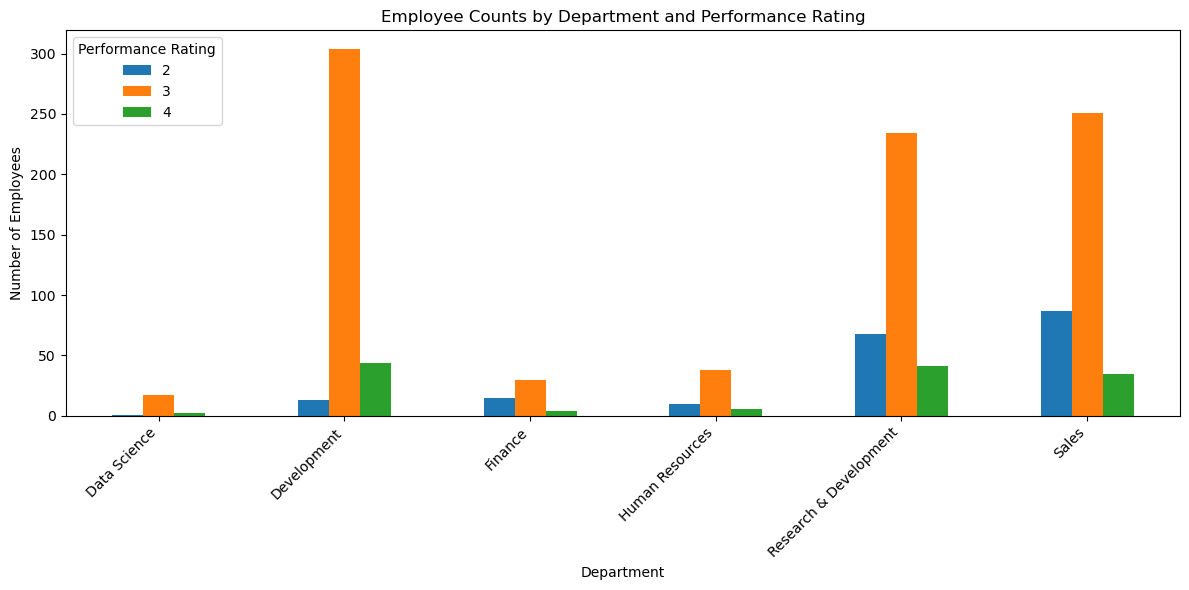

In [193]:
department_counts = pd.crosstab(
    df['PerformanceRating'],
    df['EmpDepartment']
)

department_counts.T.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title('Employee Counts by Department and Performance Rating')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Performance Rating')
plt.tight_layout()
plt.show()

In [189]:
df['PerformanceRating'].value_counts()
performance_by_department = pd.crosstab(df['EmpDepartment'], df['PerformanceRating'], normalize='index')*100
performance_by_department

PerformanceRating,2,3,4
EmpDepartment,,,
Data Science,5.000000,85.000000,10.000000
Development,3.601108,84.210526,12.188366
Finance,30.612245,61.224490,8.163265
Human Resources,18.518519,70.370370,11.111111
Research & Development,19.825073,68.221574,11.953353
Sales,23.324397,67.292225,9.383378


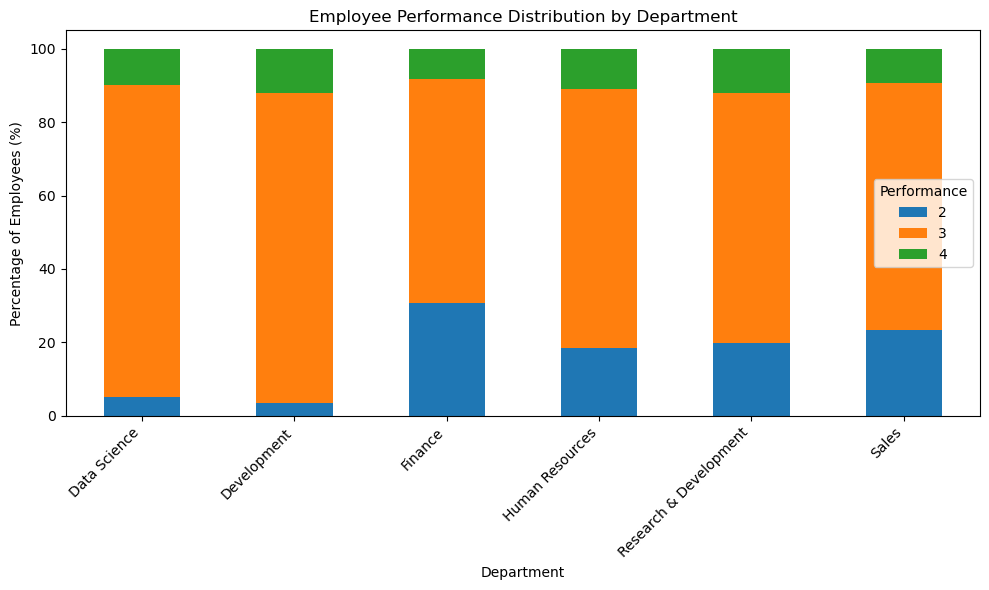

In [190]:
performance_by_department.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Employee Performance Distribution by Department')
plt.xlabel('Department')
plt.ylabel('Percentage of Employees (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Performance')
plt.tight_layout()
plt.show()

In [196]:
df['EmpJobRole'].value_counts()

EmpJobRole
Sales Executive              270
Developer                    236
Manager R&D                   94
Research Scientist            77
Sales Representative          69
Laboratory Technician         64
Senior Developer              52
Manager                       51
Finance Manager               49
Human Resources               45
Technical Lead                38
Manufacturing Director        33
Healthcare Representative     33
Data Scientist                20
Research Director             19
Business Analyst              16
Senior Manager R&D            15
Delivery Manager              12
Technical Architect            7
Name: count, dtype: int64

In [198]:
df['EmpJobRole'].value_counts(normalize='index')*100

EmpJobRole
Sales Executive              22.500000
Developer                    19.666667
Manager R&D                   7.833333
Research Scientist            6.416667
Sales Representative          5.750000
Laboratory Technician         5.333333
Senior Developer              4.333333
Manager                       4.250000
Finance Manager               4.083333
Human Resources               3.750000
Technical Lead                3.166667
Manufacturing Director        2.750000
Healthcare Representative     2.750000
Data Scientist                1.666667
Research Director             1.583333
Business Analyst              1.333333
Senior Manager R&D            1.250000
Delivery Manager              1.000000
Technical Architect           0.583333
Name: proportion, dtype: float64

In [200]:
performance_by_jobrole = pd.crosstab(df['EmpJobRole'], df['PerformanceRating'], normalize='index')*100
performance_by_jobrole

PerformanceRating,2,3,4
EmpJobRole,,,
Business Analyst,0.000000,81.250000,18.750000
Data Scientist,5.000000,85.000000,10.000000
Delivery Manager,0.000000,100.000000,0.000000
Developer,2.542373,84.322034,13.135593
Finance Manager,30.612245,61.224490,8.163265
Healthcare Representative,24.242424,66.666667,9.090909
Human Resources,20.000000,68.888889,11.111111
Laboratory Technician,21.875000,70.312500,7.812500
Manager,23.529412,56.862745,19.607843


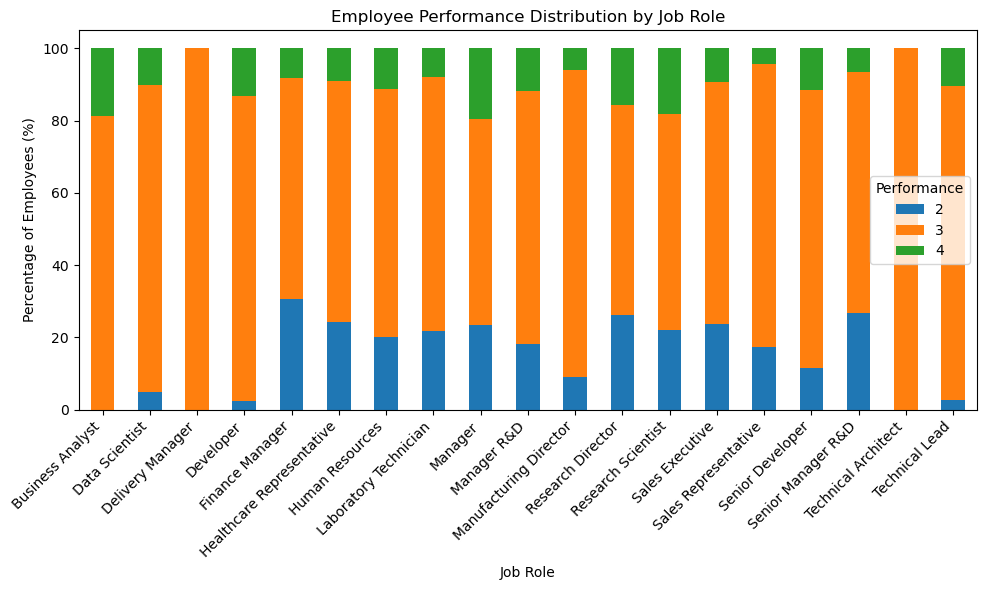

In [201]:
performance_by_jobrole.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Employee Performance Distribution by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Percentage of Employees (%)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Performance')
plt.tight_layout()
plt.show()

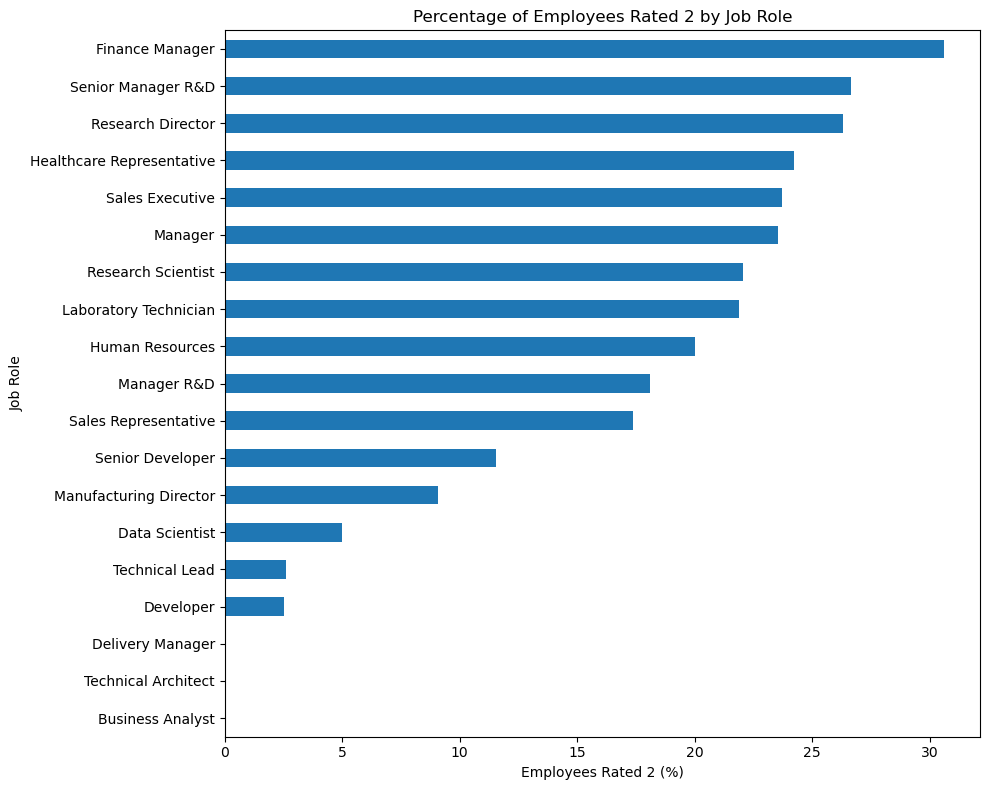

In [203]:
performance_by_jobrole[2].sort_values().plot(
    kind='barh',
    figsize=(10, 8)
)

plt.title('Percentage of Employees Rated 2 by Job Role')
plt.xlabel('Employees Rated 2 (%)')
plt.ylabel('Job Role')
plt.tight_layout()
plt.show()

Employee Performance Across Departments and Job Roles

The descriptive analysis revealed differences in employee performance ratings across departments and job roles. Most employees across departments received a performance rating of 3, indicating that this was the most common rating in the dataset.

At the departmental level, Finance had the highest proportion of employees rated 2 (30.61%), followed by Sales (23.32%). Development had the lowest proportion of employees rated 2 (3.60%) and the highest proportion rated 4 (12.19%).

At the job-role level, Finance Managers had the highest proportion of employees rated 2 (30.61%), followed by Healthcare Representatives (24.24%) and Sales Executives (23.70%). Managers had the highest proportion rated 4 (19.61%), followed by Research Scientists (18.18%) and Business Analysts (18.75%).

Business Analysts, Delivery Managers, and Technical Architects had no employees rated 2. However, Delivery Managers and Technical Architects also had no employees rated 4, with all observed employees receiving rating 3.

Overall, the findings suggest that employee performance ratings vary across departments and job roles. These differences identify groups that may warrant further investigation but do not establish the causes of performance differences. Employee counts should also be considered when interpreting percentages, particularly for job roles with small sample sizes.

In [ ]:

ordinal_categorical = ['EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpJobInvolvement', 
'EmpJobLevel', 'EmpJobSatisfaction', 'EmpRelationshipSatisfaction', 'EmpWorkLifeBalance', 'PerformanceRating']

ordinal_categorical = df[ordinal_categorical].astype('int')

travel_mapping = {"Non-Travel": 0, "Travel_Rarely": 1, "Travel_Frequently": 2}
df["BusinessTravelFrequency"] = df["BusinessTravelFrequency"].map(
    travel_mapping
)

for col in ordinal_categorical:
    df[col] = df[col].astype(int)

nominal_categorical_1 = [
"EducationBackground",
"EmpDepartment",
"EmpJobRole",
"MaritalStatus"]


nominal_categorical_2 = ["Attrition",
"Gender",
"OverTime",
]

replacement_map = {
    "Attrition": {"No": 0, "Yes": 1},
    "OverTime": {"No": 0, "Yes": 1},
    "Gender": {"Female": 0, "Male": 1}
}
for col, mapping in replacement_map.items():
    if col in df.columns:
        df[col] = df[col].replace(mapping).astype("int8")

df = pd.get_dummies(df, columns=nominal_categorical_1, drop_first=True, dtype=int)

numerical_columns = ["Age",
    "DistanceFromHome",
    "EmpHourlyRate",
    "NumCompaniesWorked",
    "EmpLastSalaryHikePercent",
    "TotalWorkExperienceInYears",
    "TrainingTimesLastYear",
    "ExperienceYearsAtThisCompany",
    "ExperienceYearsInCurrentRole",
    "YearsSinceLastPromotion",
    "YearsWithCurrManager",
]

scaler = StandardScaler()
df[numerical_columns] = scaler.fit_transform(df[numerical_columns])


In [ ]:
x = df.drop(columns=["PerformanceRating", "EmpNumber"])
y = df["PerformanceRating"]

In [ ]:
print(x.isna().sum()[x.isna().sum() > 0])


Series([], dtype: int64)


In [ ]:
from scipy.stats import spearmanr

# Calculate Spearman rank correlation and p-value for every feature against PerformanceRating
corr_results = []
for col in x_train_model.columns:
    rho, p_val = spearmanr(x_train_model[col], y_train)
    corr_results.append({
        'Feature': col,
        'Spearman_r': rho,
        'Bivariate_p_value': p_val
    })

corr_df = pd.DataFrame(corr_results).set_index('Feature')

# Combine with your multivariate OrderedModel p-values and coefs for a master EDA table
corr_df['Multivariate_coef'] = feature_df['coef']
corr_df['Multivariate_p_value'] = feature_df['p_value']
corr_df['Odds_Ratio'] = feature_df['odds_ratio']

# Filter to show anything significant in EITHER bivariate correlation OR multivariate regression
sig_analysis = corr_df[(corr_df['Bivariate_p_value'] < 0.05) | (corr_df['Multivariate_p_value'] < 0.05)]
sig_analysis = sig_analysis.sort_values(by='Multivariate_p_value')

print("Master Correlation & Statistical Significance Table:")
display(sig_analysis.round(4))


Master Correlation & Statistical Significance Table:


,Spearman_r,Bivariate_p_value,Multivariate_coef,Multivariate_p_value,Odds_Ratio
Feature,,,,,
EmpEnvironmentSatisfaction,0.4125,0.0000,1.3341,0.0000,3.7965
EmpLastSalaryHikePercent,0.2987,0.0000,1.2067,0.0000,3.3423
EmpWorkLifeBalance,0.0850,0.0084,0.5390,0.0000,1.7144
ExperienceYearsInCurrentRole,-0.1745,0.0000,-0.5941,0.0000,0.5521
YearsSinceLastPromotion,-0.2840,0.0000,-0.3711,0.0005,0.6900
EmpJobRole_Finance Manager,-0.0723,0.0250,-2.0933,0.0034,0.1233
EducationBackground_Medical,-0.0222,0.4912,-0.3976,0.0479,0.6720
ExperienceYearsAtThisCompany,-0.1392,0.0000,0.3509,0.0604,1.4204
EmpDepartment_Sales,-0.1121,0.0005,-2.1593,0.1625,0.1154


In [ ]:
x = df.drop(columns=["PerformanceRating", "EmpNumber"])
y = df["PerformanceRating"]

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("Classification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[ 17  11   1]
 [ 14 168   2]
 [  0   8  19]]
Classification Report:
              precision    recall  f1-score   support

           2       0.55      0.59      0.57        29
           3       0.90      0.91      0.91       184
           4       0.86      0.70      0.78        27

    accuracy                           0.85       240
   macro avg       0.77      0.73      0.75       240
weighted avg       0.85      0.85      0.85       240



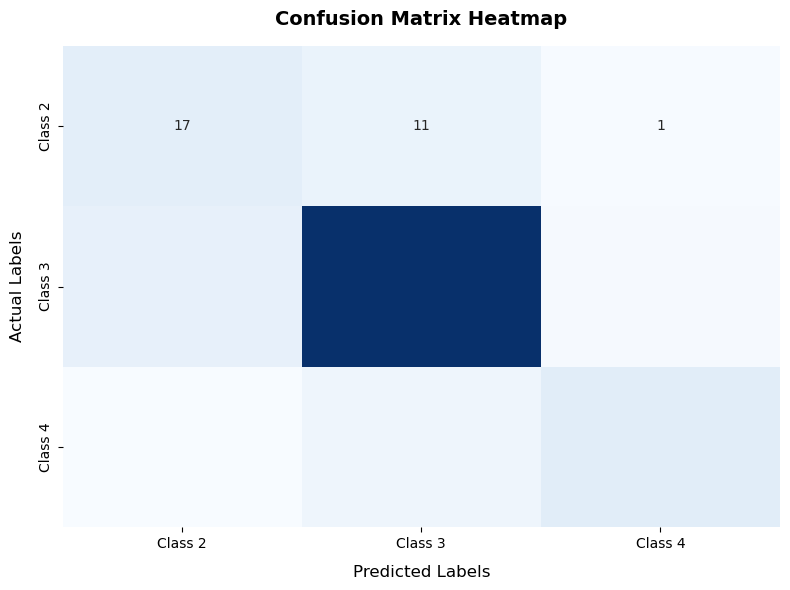

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# 1. Compute confusion matrix using your test data
cm = confusion_matrix(y_test, y_pred)

# 2. Build the visual heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Class 2", "Class 3", "Class 4"],
    yticklabels=["Class 2", "Class 3", "Class 4"],
    cbar=False,
)

# 3. Add labels and layout styling
plt.title("Confusion Matrix Heatmap", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Predicted Labels", fontsize=12, labelpad=10)
plt.ylabel("Actual Labels", fontsize=12, labelpad=10)
plt.tight_layout()

# 4. Display the plot
plt.show()


In [ ]:
feature_names = x_train.columns
coefficients = model.coef_

coef_df = pd.DataFrame(coefficients, columns=feature_names, index=[f"Effect_on_Class_{c}" for c in model.classes_]).T

print("how each column affects performance rating:")
print(coef_df)

how each column affects performance rating:
                                      Effect_on_Class_2  Effect_on_Class_3  \
Age                                           -0.070972          -0.054415   
Gender                                        -0.151947           0.112856   
BusinessTravelFrequency                       -0.093200          -0.138188   
DistanceFromHome                               0.165929           0.031923   
EmpEducationLevel                             -0.239914           0.090092   
EmpEnvironmentSatisfaction                    -1.533917           0.484464   
EmpHourlyRate                                  0.119396          -0.085505   
EmpJobInvolvement                              0.017499           0.134131   
EmpJobLevel                                    0.172098          -0.165858   
EmpJobSatisfaction                            -0.046433          -0.002931   
NumCompaniesWorked                             0.056361          -0.089646   
OverTime            

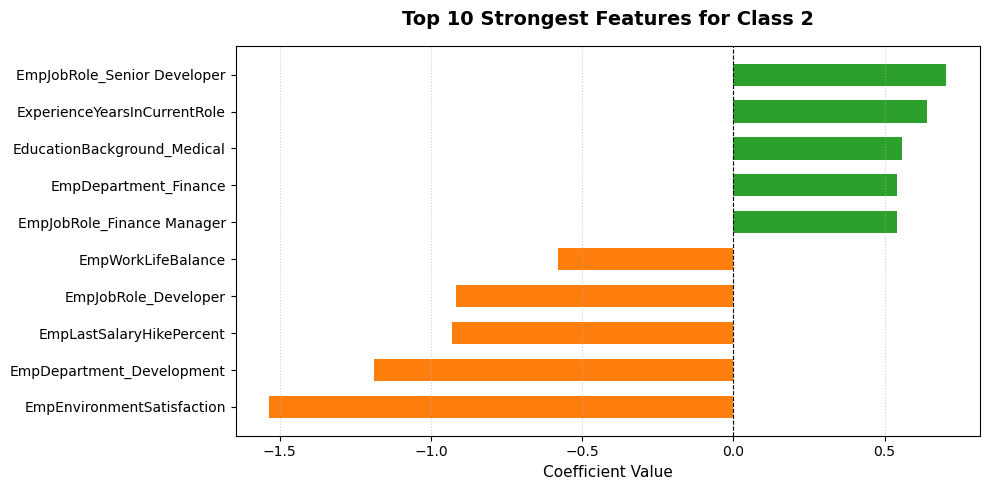

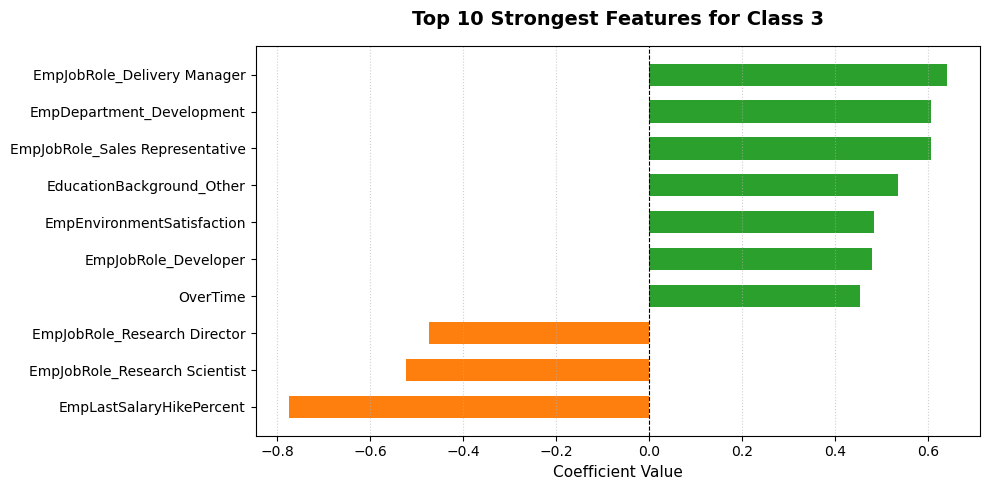

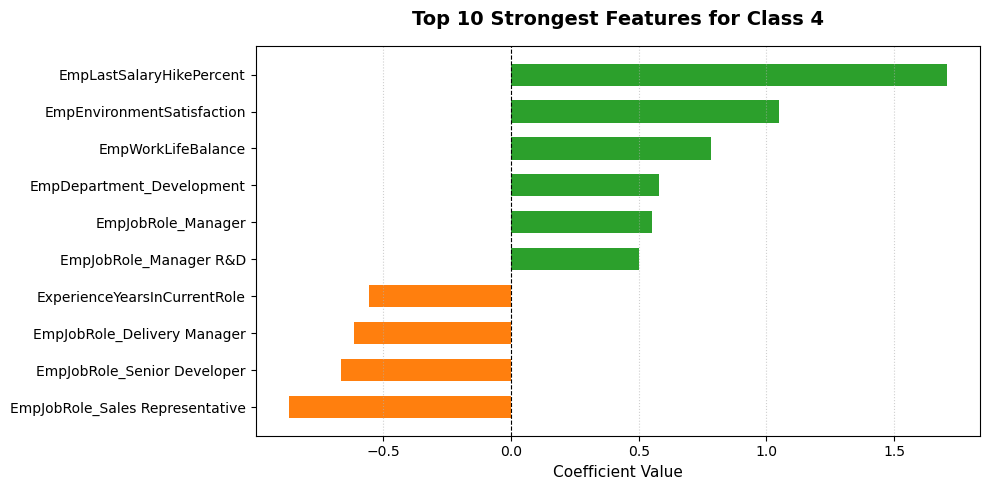

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

# 1. Rebuild the dataframe
feature_names = x_train.columns
coef_df = pd.DataFrame(
    model.coef_,
    columns=feature_names,
    index=[f"Class {c}" for c in model.classes_],
).T

# 2. Plot ONLY the top 10 most impactful features per class
for target_class in coef_df.columns:
    # Sort features by absolute impact
    sorted_df = coef_df[[target_class]].copy()
    sorted_df["abs_val"] = sorted_df[target_class].abs()
    sorted_df = sorted_df.sort_values(by="abs_val", ascending=False)

    # Keep only the top 10 strongest columns (drop the zero/tiny noise)
    top_10 = sorted_df.head(10).sort_values(by=target_class, ascending=True)

    # Plotting code with ample vertical spacing
    plt.figure(figsize=(10, 5))
    colors = [
        "#2ca02c" if val >= 0 else "#ff7f0e"
        for val in top_10[target_class].values
    ]

    plt.barh(top_10.index, top_10[target_class].values, color=colors, height=0.6)
    plt.axvline(0, color="black", linestyle="--", linewidth=0.8)

    plt.title(
        f"Top 10 Strongest Features for {target_class}",
        fontsize=14,
        fontweight="bold",
        pad=15,
    )
    plt.xlabel("Coefficient Value", fontsize=11)

    # Clean adjustments to prevent overlaps
    plt.yticks(fontsize=10)
    plt.grid(axis="x", linestyle=":", alpha=0.6)
    plt.tight_layout()
    plt.show()


drop attrition and overtime

In [ ]:
# Combine temporarily to drop rows that contain NaNs in either X or Y
import pandas as pd

# Check if there are any NaNs present first
print("Missing values in X:", x_train.isna().sum().sum())
print("Missing values in Y:", y_train.isna().sum())

# Drop missing values cleanly
x_train = x_train.dropna()
y_train = y_train.loc[x_train.index]


Missing values in X: 0
Missing values in Y: 0


In [ ]:
print(y_train.value_counts())


PerformanceRating
3    690
2    165
4    105
Name: count, dtype: int64


In [ ]:
print(x_train.columns.tolist())

['Age', 'Gender', 'BusinessTravelFrequency', 'DistanceFromHome', 'EmpEducationLevel', 'EmpEnvironmentSatisfaction', 'EmpHourlyRate', 'EmpJobInvolvement', 'EmpJobLevel', 'EmpJobSatisfaction', 'NumCompaniesWorked', 'OverTime', 'EmpLastSalaryHikePercent', 'EmpRelationshipSatisfaction', 'TotalWorkExperienceInYears', 'TrainingTimesLastYear', 'EmpWorkLifeBalance', 'ExperienceYearsAtThisCompany', 'ExperienceYearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'Attrition', 'EducationBackground_Life Sciences', 'EducationBackground_Marketing', 'EducationBackground_Medical', 'EducationBackground_Other', 'EducationBackground_Technical Degree', 'EmpDepartment_Development', 'EmpDepartment_Finance', 'EmpDepartment_Human Resources', 'EmpDepartment_Research & Development', 'EmpDepartment_Sales', 'EmpJobRole_Data Scientist', 'EmpJobRole_Delivery Manager', 'EmpJobRole_Developer', 'EmpJobRole_Finance Manager', 'EmpJobRole_Healthcare Representative', 'EmpJobRole_Human Resources', 'EmpJob

In [ ]:
job_role_cols = [
    col for col in x_train.columns
    if col.startswith('EmpJobRole_')
]

for col in job_role_cols:
    print(f"\n{col}")
    print(pd.crosstab(x_train[col], y_train))


EmpJobRole_Data Scientist
PerformanceRating            2    3    4
EmpJobRole_Data Scientist               
0                          164  680  104
1                            1   10    1

EmpJobRole_Delivery Manager
PerformanceRating              2    3    4
EmpJobRole_Delivery Manager               
0                            165  680  105
1                              0   10    0

EmpJobRole_Developer
PerformanceRating       2    3   4
EmpJobRole_Developer              
0                     160  529  81
1                       5  161  24

EmpJobRole_Finance Manager
PerformanceRating             2    3    4
EmpJobRole_Finance Manager               
0                           152  664  102
1                            13   26    3

EmpJobRole_Healthcare Representative
PerformanceRating                       2    3    4
EmpJobRole_Healthcare Representative               
0                                     158  674  105
1                                       7   16    0

Emp

In [ ]:
job_role_cols = [
    col for col in x_train.columns
    if col.startswith('EmpJobRole_')
]

for col in job_role_cols:
    counts = pd.crosstab(x_train[col], y_train)

    role_counts = counts.loc[1]

    ratings_present = role_counts[role_counts > 0].index.tolist()

    if len(ratings_present) == 1:
        print(col, '-> Ratings:', ratings_present)

EmpJobRole_Delivery Manager -> Ratings: [3]
EmpJobRole_Technical Architect -> Ratings: [3]


In [ ]:
department_cols = [
    col for col in x_train.columns
    if col.startswith('EmpDepartment_')
]

print("Department columns:", len(department_cols))
print("Job role columns:", len(job_role_cols))

Department columns: 5
Job role columns: 18


In [ ]:
import numpy as np

X_with_const = sm.add_constant(x_train)

rank = np.linalg.matrix_rank(x_with_const.to_numpy())
n_columns = X_with_const.shape[1]

print("Number of columns:", n_columns)
print("Matrix rank:", rank)
print("Rank deficient:", rank < n_columns)

Number of columns: 53
Matrix rank: 50
Rank deficient: True


In [ ]:
pd.crosstab(
    df.loc[x_train.index, 'EmpJobRole'],
    y_train
)

KeyError: 'EmpJobRole'

In [ ]:
pd.crosstab(
    x_train['EmpJobRole'],
    y_train
)

KeyError: 'EmpJobRole'

In [ ]:
from scipy.linalg import qr
import numpy as np
import statsmodels.api as sm

x_with_const = sm.add_constant(x_train_model).astype(float)

# QR decomposition with column pivoting
Q, R, pivots = qr(
    x_with_const.to_numpy(),
    pivoting=True,
    mode='economic'
)

rank = np.linalg.matrix_rank(x_with_const.to_numpy())

independent_cols = x_with_const.columns[pivots[:rank]]
dependent_cols = x_with_const.columns[pivots[rank:]]

print("Matrix rank:", rank)
print("\nPotentially redundant columns:")
print(dependent_cols.tolist())

Matrix rank: 48

Potentially redundant columns:
['EmpJobRole_Senior Manager R&D', 'EmpDepartment_Finance']


In [ ]:
print(x_train_model[department_cols + job_role_cols].corr().round(2))

KeyError: "['EmpDepartment_Development', 'EmpJobRole_Data Scientist'] not in index"

In [ ]:
x_train_model = x_train.drop(columns=[
    'EducationBackground_Life Sciences',
    'EmpDepartment_Development',
    'EmpJobRole_Data Scientist',
    'EmpJobRole_Senior Manager R&D',
    'EmpDepartment_Finance'
])

In [ ]:
X_with_const = sm.add_constant(x_train_model).astype(float)

rank = np.linalg.matrix_rank(X_with_const.to_numpy())
n_columns = X_with_const.shape[1]

print("Number of columns:", n_columns)
print("Matrix rank:", rank)
print("Rank deficient:", rank < n_columns)

Number of columns: 48
Matrix rank: 48
Rank deficient: False


In [ ]:
print(y_train.value_counts().sort_index())
print(y_train.value_counts(normalize=True).sort_index() * 100)

PerformanceRating
2    165
3    690
4    105
Name: count, dtype: int64
PerformanceRating
2    17.1875
3    71.8750
4    10.9375
Name: proportion, dtype: float64


In [ ]:
from statsmodels.miscmodels.ordinal_model import OrderedModel

ordinal_model = OrderedModel(
    y_train,
    x_train_model,
    distr='logit'
)

ordinal_result = ordinal_model.fit(
    method='bfgs',
    maxiter=1000,
    disp=False
)

print(ordinal_result.summary())

                             OrderedModel Results                             
Dep. Variable:      PerformanceRating   Log-Likelihood:                -497.17
Model:                   OrderedModel   AIC:                             1092.
Method:            Maximum Likelihood   BIC:                             1331.
Date:                Fri, 30 Oct 2026                                         
Time:                        15:21:12                                         
No. Observations:                 960                                         
Df Residuals:                     911                                         
Df Model:                          47                                         
                                           coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------------
Age                                     -0.0633      0.117     -0.543      0.58

In [ ]:
import numpy as np
import pandas as pd

# Build a clean summary dataframe from your fitted model
summary_df = pd.DataFrame({
    'coef': ordinal_result.params,
    'std_err': ordinal_result.bse,
    'z': ordinal_result.tvalues,
    'p_value': ordinal_result.pvalues,
    'odds_ratio': np.exp(ordinal_result.params)
})

# Separate features from threshold cutpoints (2/3, 3/4)
feature_df = summary_df.drop(index=['2/3', '3/4'])

# Filter for statistically significant features (p < 0.05) and sort by impact
sig_features = feature_df[feature_df['p_value'] < 0.05].sort_values(by='odds_ratio', ascending=False)
print("Statistically Significant Drivers (p < 0.05):")
display(sig_features.round(4))


Statistically Significant Drivers (p < 0.05):


,coef,std_err,z,p_value,odds_ratio
EmpEnvironmentSatisfaction,1.3341,0.1012,13.1765,0.0000,3.7965
EmpLastSalaryHikePercent,1.2067,0.1000,12.0670,0.0000,3.3423
EmpWorkLifeBalance,0.5390,0.1225,4.4017,0.0000,1.7144
YearsSinceLastPromotion,-0.3711,0.1068,-3.4734,0.0005,0.6900
EducationBackground_Medical,-0.3976,0.2009,-1.9785,0.0479,0.6720
ExperienceYearsInCurrentRole,-0.5941,0.1435,-4.1403,0.0000,0.5521
EmpJobRole_Finance Manager,-2.0933,0.7144,-2.9301,0.0034,0.1233


In [ ]:
# Select features with p < 0.10 from the initial run (excluding thresholds)
keep_cols = feature_df[feature_df['p_value'] < 0.10].index.tolist()

# Optional: If EmpLastSalaryHikePercent is post-review target leakage, uncomment below:
# keep_cols.remove('EmpLastSalaryHikePercent')

# Refit the pruned OrderedModel
ordinal_model_pruned = OrderedModel(
    y_train,
    x_train_model[keep_cols],
    distr='logit'
)

ordinal_result_pruned = ordinal_model_pruned.fit(
    method='bfgs',
    maxiter=1000,
    disp=False
)

print(f"Original AIC: {ordinal_result.aic:.1f} | Pruned AIC: {ordinal_result_pruned.aic:.1f}")
print(f"Original BIC: {ordinal_result.bic:.1f} | Pruned BIC: {ordinal_result_pruned.bic:.1f}")
print(ordinal_result_pruned.summary())


Original AIC: 1092.3 | Pruned AIC: 1090.1
Original BIC: 1330.8 | Pruned BIC: 1143.6
                             OrderedModel Results                             
Dep. Variable:      PerformanceRating   Log-Likelihood:                -534.04
Model:                   OrderedModel   AIC:                             1090.
Method:            Maximum Likelihood   BIC:                             1144.
Date:                Fri, 30 Oct 2026                                         
Time:                        15:30:38                                         
No. Observations:                 960                                         
Df Residuals:                     949                                         
Df Model:                           9                                         
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
EmpEducatio

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict probabilities on x_test (ensure same columns as training)
pred_probs = ordinal_result_pruned.predict(x_test[keep_cols])

# Map highest probability column (0, 1, 2) back to actual rating labels (2, 3, 4)
classes = np.sort(y_train.unique())
y_pred = classes[np.argmax(pred_probs.values, axis=1)]

print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           2       0.33      0.17      0.23        29
           3       0.82      0.95      0.88       184
           4       1.00      0.44      0.62        27

    accuracy                           0.80       240
   macro avg       0.72      0.52      0.57       240
weighted avg       0.78      0.80      0.77       240



The classification model achieved 80% accuracy and a weighted F1-score of 0.77. However, performance varied considerably across the three rating categories. The model achieved an F1-score of 0.88 for rating 3 but only 0.23 for rating 2 and 0.62 for rating 4. In particular, the recall for rating 2 was 17%, indicating that the model failed to identify most employees in this category. The macro F1-score of 0.57 further highlights the uneven classification performance. Although the model demonstrates potential, further evaluation and optimisation are needed before it can reliably support employee performance improvement initiatives.

Statistical Analysis of Employee Performance

To investigate which factors are associated with employee performance ratings, two statistical methods were used:

* Spearman rank correlation: Examines the direction and strength of the relationship between individual features and performance ratings.
* Ordinal logistic regression (OrderedModel): Examines the relationship between multiple features and performance ratings simultaneously, accounting for the other variables included in the model.

The target variable, PerformanceRating, has three possible categories: 2, 3, and 4. Because these categories have a natural order, ordinal logistic regression is appropriate for investigating the factors associated with higher or lower ratings.

The initial correlation analysis identified 18 features with statistically significant relationships with performance ratings. However, several of these relationships were no longer statistically significant after other variables were included in the regression model.

This difference highlights the importance of examining individual relationships alongside multivariate analysis.

1. Key Findings

The following table summarises the seven features reported as statistically significant in the pruned regression model.

Feature	Spearman Correlation	Pruned Model Coefficient	Odds Ratio	Interpretation
EmpEnvironmentSatisfaction	0.4125	1.2328	3.43	Higher environment satisfaction is associated with higher performance ratings.
EmpLastSalaryHikePercent	0.2987	1.1395	3.13	Higher salary hike values are associated with higher performance ratings.
EmpWorkLifeBalance	0.0850	0.4588	1.58	Better work-life balance is associated with higher performance ratings.
ExperienceYearsInCurrentRole	-0.1745	-0.5855	0.56	More years in the current role are associated with lower performance ratings, after adjusting for the other included variables.
YearsSinceLastPromotion	-0.2840	-0.3986	0.67	Longer periods since the last promotion are associated with lower performance ratings.
EmpJobRole_Finance Manager	-0.0723	-1.1791	0.31	Finance Managers have lower estimated odds of higher ratings than employees in the reference job role.
ExperienceYearsAtThisCompany	-0.1392	0.3705	1.45	Company tenure has a positive adjusted association with performance ratings.

How to interpret the odds ratios

An odds ratio greater than 1 indicates higher odds of being in a higher performance category, while an odds ratio below 1 indicates lower odds, holding the other included variables constant.

For example, the odds ratio of 3.43 for environment satisfaction indicates approximately 3.43 times the odds of receiving a higher performance rating for a one-unit increase in the satisfaction score.

Similarly, an odds ratio of 0.56 for years in the current role indicates approximately 44% lower odds of a higher performance rating for a one-unit increase in that variable.

These interpretations assume the model’s proportional-odds structure is appropriate and that the variables are correctly encoded. The odds ratios describe associations, not changes in the probability of receiving a particular rating.

Note: The reported odds ratios should be recalculated from the final fitted model before publication. In particular, verify that the Finance Manager coefficient used here is -1.1791 and that its corresponding odds ratio is approximately 0.31.

2. Factors Associated with Employee Performance

Employee satisfaction and salary increases

Environment satisfaction had the strongest positive coefficient in the pruned model. Employees reporting higher satisfaction with their work environment tended to have higher performance ratings, even after accounting for the other variables included in the model.

Salary hike percentage was also positively associated with performance ratings. This suggests that salary increases and performance ratings tend to move in the same direction in this dataset.

Work-life balance showed a positive association as well, although its Spearman correlation was relatively weak. Its statistical significance in the regression model suggests that its relationship with performance may be clearer after accounting for other included variables.

These findings identify potential areas for further investigation, but they do not establish that improving satisfaction, increasing salaries, or changing work-life balance will necessarily cause performance ratings to increase.

Career progression and time in a role

Two career-related variables had negative regression coefficients.

Employees who had spent more years in their current roles tended to have lower performance ratings after adjusting for the other model variables. A similar pattern was observed for employees who had gone longer without a promotion.

These associations may reflect differences in career progression, promotion opportunities, role changes, or other factors not captured by the model. They should not be interpreted as evidence that experience itself reduces employee performance.

Differences between job roles

The Finance Manager indicator had a negative coefficient in the pruned model.

This suggests that Finance Managers had lower estimated odds of receiving higher performance ratings than employees in the reference job role, after accounting for the other included variables.

The comparison depends on the reference category used when encoding job roles. It does not establish that Finance Managers perform worse overall, because job responsibilities, evaluation standards, and other differences between roles may influence the ratings.

3. Why Correlation and Regression Produced Different Results

Spearman correlation examines the relationship between two variables at a time. Ordinal logistic regression examines multiple variables together.

When features are related to one another, the association observed in a bivariate analysis may weaken, disappear, or change direction after other variables are included in the model.

Company tenure: a change in direction

Spearman correlation identified a negative relationship between ExperienceYearsAtThisCompany and performance ratings:

* Spearman correlation: -0.1392
* Pruned regression coefficient: 0.3705
* Pruned model p-value: 0.005

The regression coefficient changed from negative to positive.

This suggests that the relationship between company tenure and performance depends on other employee characteristics included in the model. For example, company tenure may overlap with years spent in the current role and time since the last promotion.

After accounting for the other included variables, longer company tenure was positively associated with performance ratings.

This is a reversal in the direction of an adjusted association. Although such reversals can occur in Simpson’s paradox, the coefficient change alone is insufficient to establish that Simpson’s paradox has occurred.

The result should also not be interpreted as proof that company loyalty improves performance. Other unmeasured factors may explain some or all of the association.

Features that lost statistical significance

Several features were statistically significant in the initial correlation analysis but were no longer significant in the reported regression results.

Feature	Spearman Correlation	Bivariate p-value	Full Model p-value	Interpretation
YearsWithCurrManager	-0.1387	< 0.0001	0.9677	No clear independent association was detected in the full model.
TotalWorkExperienceInYears	-0.0741	0.0217	0.6433	The initial association did not remain statistically significant.
EmpJobLevel	-0.0733	0.0231	0.3554	The initial association did not remain statistically significant.
EmpDepartment_Sales	-0.1121	0.0005	0.1625	The initial association did not remain statistically significant.
EmpJobRole_Sales Executive	-0.1104	0.0006	0.6385	The initial association did not remain statistically significant.
EmpJobRole_Developer	0.1567	< 0.0001	0.6362	The initial association did not remain statistically significant.
OverTime	0.0675	0.0365	0.2328	No statistically significant adjusted association was detected.

Age, gender, marital status, and attrition were also reported as statistically insignificant in the regression analysis.

These results suggest that the initial bivariate relationships may overlap with other measured employee characteristics.

However, a variable becoming statistically insignificant does not prove that it has no relationship with performance. It means the model did not provide sufficient evidence of an adjusted association at the chosen significance threshold.

Likewise, statistical significance in a multivariate model does not prove that a feature is independent of every possible confounding factor.

4. Comparing the Full and Pruned Models

The initial model included a relatively large number of predictors, including several overlapping measures of employee tenure and one-hot encoded job roles and departments.

The model was subsequently simplified by removing predictors that did not meet the selected significance threshold.

Model Metric	Full Model	Pruned Model
Model degrees of freedom	47	9
AIC	1092.3	1090.1
BIC	1330.8	1143.6
Log-likelihood	-497.17	-534.04

The pruned model had a slightly lower Akaike Information Criterion (AIC) and a substantially lower Bayesian Information Criterion (BIC).

Both criteria balance model fit against model complexity, with BIC applying a stronger penalty for additional parameters. Their values therefore favour the pruned model among these two reported specifications.

However, the full model had a higher log-likelihood, indicating a better fit to the observed data before accounting for model complexity. This is consistent with the full model having more parameters.

The pruned model offers a more compact explanation of the observed associations. Nevertheless, selecting variables solely according to their p-values can introduce bias and overstate the significance of the retained features. The comparison should therefore be treated as exploratory rather than definitive evidence that the pruned model is superior.

5. Model Assumptions and Limitations

Before drawing firm conclusions, several additional checks are necessary:

* Proportional-odds assumption: Ordinal logistic regression assumes that the relationship between the predictors and the cumulative odds is consistent across rating thresholds. This assumption should be assessed using an appropriate diagnostic.
* Multicollinearity: Overlapping tenure measures and encoded job categories may produce unstable coefficients. Variance inflation factors, condition diagnostics, and coefficient stability checks can help identify these issues.
* Variable selection: Removing variables based on p-values can make the final results sensitive to the selection procedure. The reported p-values should be interpreted with this limitation in mind.
* Multiple testing: Testing many features individually increases the likelihood of false-positive findings. A correction such as the Benjamini–Hochberg procedure could be considered for the Spearman correlation results.
* Predictive performance: A lower AIC or BIC does not automatically mean that a model predicts new observations more accurately. Predictive performance should be assessed separately using appropriate validation procedures.
* Causality: The analysis is observational. It identifies associations between employee characteristics and performance ratings but does not establish cause-and-effect relationships.

6. Overall Conclusion

The analysis identified seven features reported as statistically significant in the pruned ordinal logistic regression model: environment satisfaction, salary hike percentage, work-life balance, years in the current role, years since the last promotion, Finance Manager job role, and years at the company.

Environment satisfaction and salary hike percentage showed the strongest positive adjusted associations with performance ratings. Work-life balance was also positively associated with higher ratings. In contrast, more time in the current role and longer periods without promotion were associated with lower ratings.

Company tenure showed a different pattern after adjustment: its relationship with performance changed from negative in the bivariate analysis to positive in the pruned regression model. This demonstrates why individual correlations should not be interpreted in isolation.

Overall, the findings suggest that employee satisfaction, compensation-related measures, and career progression are relevant to understanding performance ratings in this dataset. However, the results should be treated as exploratory statistical associations rather than proof of causal drivers. Further diagnostic testing and validation are needed before using these findings to guide employee management decisions.